<a href="https://colab.research.google.com/github/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment_7_House_Price_JMV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Assignment 7:  House Price Prediction Using Boston Housing Data**

**Course:** Data Analytics and Artificial Intelligence

**Student name:** Jean Marie Vianney Munyeshyaka

**Date:** 25 November 2026

**Link to Github and Colab**

**Colab**
https://colab.research.google.com/drive/1aZNFeyYP7J3vf2g1uT4KAsD3pUCM7UeX?usp=sharing

**GitHub**

https://github.com/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment_7_House_Price_JMV.ipynb

##**1. IMPORT REQUIRED LIBRARIES**

In [5]:
# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Boston Housing Dataset
from sklearn.datasets import fetch_openml

# Train-test split
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Machine Learning Model
from sklearn.ensemble import RandomForestRegressor

# Model Evaluation Metrics
from sklearn.metrics import mean_squared_error, r2_score

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

##**2. Data Collection and Loading**

In [6]:
# ============================================================
# LOAD BOSTON HOUSING DATASET
# ============================================================

# Load the Boston Housing dataset from OpenML
boston = fetch_openml(name='boston', version=1, as_frame=True)

# Convert dataset to DataFrame
df = boston.frame

# Rename target column to MEDV if necessary
df.rename(columns={'target': 'MEDV'}, inplace=True)

# Display first 5 rows
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


##**3. Quick Check of Data**

In [8]:
# Display information about dataset
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 non-null    float64 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float64 
 5   RM       506 non-null    float64 
 6   AGE      506 non-null    float64 
 7   DIS      506 non-null    float64 
 8   RAD      506 non-null    category
 9   TAX      506 non-null    float64 
 10  PTRATIO  506 non-null    float64 
 11  B        506 non-null    float64 
 12  LSTAT    506 non-null    float64 
 13  MEDV     506 non-null    float64 
dtypes: category(2), float64(12)
memory usage: 49.0 KB


In [9]:
# Summary statistics
print("Statistical Summary:")
df.describe()

Statistical Summary:


,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.554695,6.284634,68.574901,3.795043,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.115878,0.702617,28.148861,2.105710,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.385000,3.561000,2.900000,1.129600,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.449000,5.885500,45.025000,2.100175,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.538000,6.208500,77.500000,3.207450,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.624000,6.623500,94.075000,5.188425,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,0.871000,8.780000,100.000000,12.126500,711.000000,22.000000,396.900000,37.970000,50.000000


In [10]:
# ============================================================
# FEATURES AND TARGET VARIABLE
# ============================================================

print("Features:")
print(df.columns[:-1])

print("\nTarget Variable:")
print("MEDV (Median House Value)")

# Identify categorical and continuous variables
print("\nCategorical Feature:")
print("CHAS (0 = No river, 1 = Near river)")

print("\nContinuous Features:")
for col in df.columns:
    if col != "CHAS":
        print(col)

Features:
Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT'],
      dtype='object')

Target Variable:
MEDV (Median House Value)

Categorical Feature:
CHAS (0 = No river, 1 = Near river)

Continuous Features:
CRIM
ZN
INDUS
NOX
RM
AGE
DIS
RAD
TAX
PTRATIO
B
LSTAT
MEDV


##**4. EDA and Data Preprocessing**

**Check Missing Values**

In [11]:
# ============================================================
# CHECK FOR MISSING VALUES
# ============================================================

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


**Scatter Plot Example**

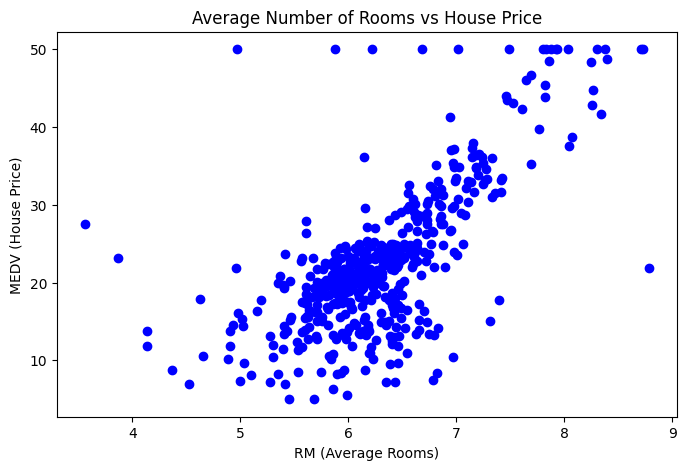

In [12]:
# ============================================================
# SCATTER PLOT: RM vs MEDV
# ============================================================

plt.figure(figsize=(8,5))

plt.scatter(df['RM'], df['MEDV'], color='blue')

plt.title("Average Number of Rooms vs House Price")
plt.xlabel("RM (Average Rooms)")
plt.ylabel("MEDV (House Price)")

plt.show()

**Function for Multiple Scatter Plots**

In [15]:
# ============================================================
# FUNCTION TO CREATE SCATTER PLOTS
# ============================================================

def plot_feature_vs_target(data, features, target):

    """
    Creates scatter plots for selected features
    against the target variable.

    Parameters:
    data     : DataFrame
    features : List of feature names
    target   : Target variable
    """

    for feature in features:

        plt.figure(figsize=(7,4))

        plt.scatter(data[feature], data[target], alpha=0.6)

        plt.title(f"{feature} vs {target}")
        plt.xlabel(feature)
        plt.ylabel(target)

        plt.show()

**Use Function**

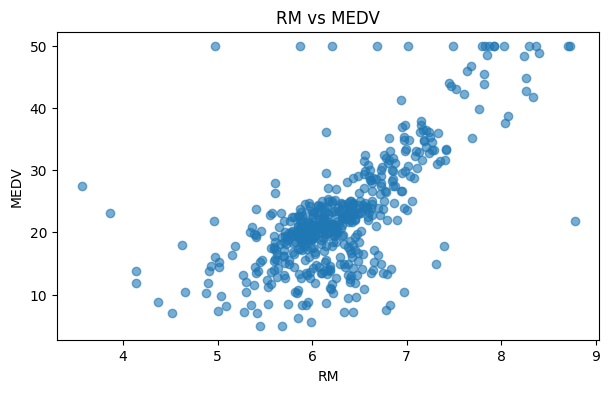

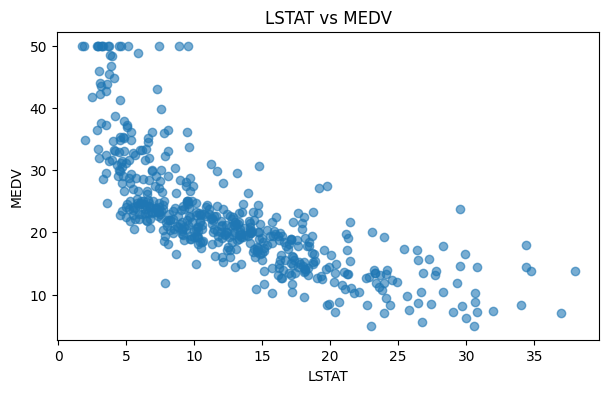

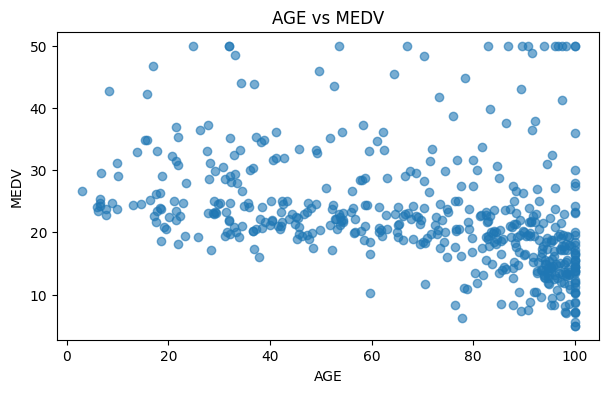

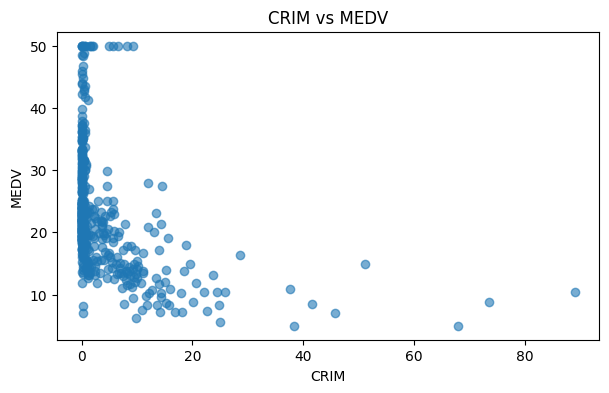

In [16]:
# ============================================================
# VISUALIZE MULTIPLE FEATURES
# ============================================================

selected_features = ['RM', 'LSTAT', 'AGE', 'CRIM']

plot_feature_vs_target(df, selected_features, 'MEDV')

##**5. ML Model Training**

In [17]:
# ============================================================
# DEFINE FEATURES (X) AND TARGET (y)
# ============================================================

X = df.drop('MEDV', axis=1)

y = df['MEDV']

In [18]:
# ============================================================
# SPLIT DATA INTO TRAINING AND TESTING SETS
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Set Size:", X_train.shape)
print("Testing Set Size:", X_test.shape)

Training Set Size: (404, 13)
Testing Set Size: (102, 13)


**Random Forest Model**

In [19]:
# ============================================================
# CREATE RANDOM FOREST REGRESSOR
# ============================================================

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

**Train the Model**

In [20]:
# ============================================================
# TRAIN THE MODEL
# ============================================================

rf_model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


##**6. Model Evaluation**
**Predictions**

In [21]:
# ============================================================
# MAKE PREDICTIONS ON TEST DATA
# ============================================================

y_pred = rf_model.predict(X_test)

**CALCULATE EVALUATION METRICS RMSE and R²**

In [22]:
# ============================================================
# CALCULATE EVALUATION METRICS
# ============================================================

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("RMSE:", rmse)
print("R-Squared:", r2)

Model Evaluation Results
-------------------------
RMSE: 2.8109631609391226
R-Squared: 0.8922527442109116


**Parameter Tuning**

In [23]:
# ============================================================
# HYPERPARAMETER TUNING USING GRID SEARCH
# ============================================================

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'n_estimators': 100}


**TRAIN BEST MODEL FOUND BY GRID SEARCH**

In [24]:
# ============================================================
# TRAIN BEST MODEL FOUND BY GRID SEARCH
# ============================================================

best_model = grid_search.best_estimator_

best_predictions = best_model.predict(X_test)

best_rmse = np.sqrt(mean_squared_error(y_test, best_predictions))
best_r2 = r2_score(y_test, best_predictions)

print("Tuned Model Results")
print("-------------------")
print("RMSE:", best_rmse)
print("R-Squared:", best_r2)

Tuned Model Results
-------------------
RMSE: 2.8109631609391226
R-Squared: 0.8922527442109116


##**7. Model Prediction**

In [25]:
# ============================================================
# PREDICT HOUSE PRICE FOR NEW DATA
# ============================================================

new_house = pd.DataFrame({
    'CRIM':[0.2],
    'ZN':[12.5],
    'INDUS':[7.07],
    'CHAS':[0],
    'NOX':[0.5],
    'RM':[6.5],
    'AGE':[68],
    'DIS':[4.0],
    'RAD':[2],
    'TAX':[250],
    'PTRATIO':[17],
    'B':[400],
    'LSTAT':[12]
})

predicted_price = best_model.predict(new_house)

print("Predicted House Price:")
print(predicted_price[0], "($1000s)")

Predicted House Price:
22.18900000000001 ($1000s)


##**Conclusion**


The Boston Housing dataset was successfully analyzed to develop a machine learning model for predicting house prices. After performing exploratory data analysis, checking for missing values, and visualizing the relationships between features and the target variable, a Random Forest Regressor was trained using an 80/20 train-test split. The model achieved a Root Mean Squared Error (RMSE) of 2.81, indicating that the average prediction error was relatively low. The model also achieved an R-squared value of 0.8923, meaning that approximately 89.23% of the variation in house prices was explained by the model. Hyperparameter tuning did not further improve the performance, as the tuned model produced the same RMSE and R-squared values. Finally, the trained model was used to predict the price of a new house, resulting in an estimated value of 22.19 ($1000s), or approximately $22,190. These results demonstrate that the Random Forest model is highly effective for predicting house prices using the Boston Housing dataset.